In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error


In [2]:
features_path = "../data/features.csv"
names_path = "../data/Swindon LSOA local names.xlsx"
df_features = pd.read_csv(features_path)
df_names = pd.read_excel(names_path)

df_merged = pd.merge(
    df_features,
    df_names[['LSOA21CD', 'Local LSOA21 Name']],
    on='LSOA21CD',
    how='left'
)

cols = df_merged.columns.tolist()
cols = cols[:2] + [cols[-1]] + cols[2:-1]
df_merged = df_merged[cols]
print(f"Dataset: {df_merged.shape[0]} rows, {df_merged.shape[1]} columns")
display(df_merged.head())
df_merged.info()
df_features_clean = df_features.drop_duplicates(subset=['LSOA21CD'], keep='first')

# Only remain data from the Swindon region
df_swindon = pd.merge(
    df_names[['LSOA21CD', 'Local LSOA21 Name']],
    df_features_clean,
    on='LSOA21CD',
    how='inner'
)

missing_names = df_swindon['Local LSOA21 Name'].isnull().sum()
if missing_names == 0:
    print("All matched")
else:
    print(f"Still {missing_names} area missing ")

print(len(df_swindon))
print(df_swindon.shape[1])
display(df_swindon.head())
df_swindon.info()

Dataset: 1129 rows, 84 columns


,LSOA21CD,LSOA21NM,Local LSOA21 Name,LSOA21NMW,RUC21CD,RUC21NM,Urban_rura,Shape_Leng,Shape__Are,Shape__Len,...,share_enterprises_industrial_2025_msoa,share_enterprises_kibs_2025_msoa,share_enterprises_anchor_2025_msoa,enterprises_per_1k_residents_2025,share_enterprises_public_2025_msoa,share_enterprises_private_2025_msoa,bus_stop_count,area_km2,bus_stop_density,dist_to_primary_m
0,E01015471,Swindon 028A,Blunsdon St Andrew central,NaN,UN1,Urban: Nearer to a major town or city,Urban,4013.589687,5.013996e+05,4013.589687,...,0.020833,0.458333,0.083333,105.448155,0.000000,1.000000,5,1.298791,3.849735,617.714131
1,E01015473,Swindon 008A,Stanton Fitzwarren,NaN,RSN1,Smaller rural: Nearer to a major town or city,Rural,25688.031740,1.524397e+07,25688.031738,...,0.045752,0.405229,0.065359,351.401011,0.006536,0.993464,37,39.476058,0.937277,574.697536
2,E01015475,Swindon 015A,Bathurst Road,NaN,UN1,Urban: Nearer to a major town or city,Urban,2099.250451,2.145225e+05,2099.250451,...,0.016129,0.290323,0.064516,124.298316,0.000000,1.000000,10,0.554698,18.027840,350.510113
3,E01015477,Swindon 015C,Albion Street,NaN,UN1,Urban: Nearer to a major town or city,Urban,3276.800336,2.405209e+05,3276.800336,...,0.016129,0.290323,0.064516,171.365395,0.000000,1.000000,5,0.621788,8.041327,473.126804
4,E01015478,Swindon 021A,Kingshill,NaN,UN1,Urban: Nearer to a major town or city,Urban,4188.002606,6.194380e+05,4188.002606,...,0.033898,0.406780,0.067797,181.315304,0.000000,1.000000,6,1.601008,3.747640,58.398219


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1129 entries, 0 to 1128
Data columns (total 84 columns):
 #   Column                                                                                                                                                                                                                                                                                                                                  Non-Null Count  Dtype  
---  ------                                                                                                                                                                                                                                                                                                                                  --------------  -----  
 0   LSOA21CD                                                                                                                                                                      

,LSOA21CD,Local LSOA21 Name,LSOA21NM,LSOA21NMW,RUC21CD,RUC21NM,Urban_rura,Shape_Leng,Shape__Are,Shape__Len,...,share_enterprises_industrial_2025_msoa,share_enterprises_kibs_2025_msoa,share_enterprises_anchor_2025_msoa,enterprises_per_1k_residents_2025,share_enterprises_public_2025_msoa,share_enterprises_private_2025_msoa,bus_stop_count,area_km2,bus_stop_density,dist_to_primary_m
0,E01015471,Blunsdon St Andrew central,Swindon 028A,NaN,UN1,Urban: Nearer to a major town or city,Urban,4013.589687,5.013996e+05,4013.589687,...,0.020833,0.458333,0.083333,105.448155,0.000000,1.000000,5,1.298791,3.849735,617.714131
1,E01033861,Blunsdon St Andrew east,Swindon 028G,NaN,UN1,Urban: Nearer to a major town or city,Urban,4400.538691,6.930759e+05,4400.538691,...,0.020833,0.458333,0.083333,119.820270,0.000000,1.000000,8,1.795286,4.456115,353.783011
2,E01032710,Haydon east,Swindon 028E,NaN,UN1,Urban: Nearer to a major town or city,Urban,3300.845583,4.878420e+05,3300.845583,...,0.020833,0.458333,0.083333,171.184023,0.000000,1.000000,8,1.263367,6.332287,101.370297
3,E01033860,Groundwell,Swindon 028F,NaN,UN1,Urban: Nearer to a major town or city,Urban,3093.536938,4.921624e+05,3093.536938,...,0.020833,0.458333,0.083333,129.729730,0.000000,1.000000,3,1.274531,2.353807,193.498452
4,E01033843,"Broad Blunsdon, Castle Eaton and Hannington",Swindon 008H,NaN,UN1,Urban: Nearer to a major town or city,Urban,26225.609360,2.227618e+07,26225.609356,...,0.045752,0.405229,0.065359,529.778393,0.006536,0.993464,4,57.800596,0.069203,4781.724069


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 84 columns):
 #   Column                                                                                                                                                                                                                                                                                                                                  Non-Null Count  Dtype  
---  ------                                                                                                                                                                                                                                                                                                                                  --------------  -----  
 0   LSOA21CD                                                                                                                                                                        

In [3]:
#2. Define the target and predictor variables
target_variable = 'LSOA GVA Estimates (millions)'

predictor_variables = [
    'employment_rate_per_pop',
    'VOA_total_RV_2026',
    'LU_pct_large_2025_msoa',
    'IMD_decile'
]

id_columns = ['LSOA21CD', 'Local LSOA21 Name']

print('Target:', target_variable)
print('Predictors:', predictor_variables)

Target: LSOA GVA Estimates (millions)
Predictors: ['employment_rate_per_pop', 'VOA_total_RV_2026', 'LU_pct_large_2025_msoa', 'IMD_decile']


In [13]:
# 3. Check whether all required columns exist
required_columns = (id_columns + predictor_variables + [target_variable])
missing_columns = []

for column in required_columns:
    if column not in df_swindon.columns:
        missing_columns.append(column)

if len(missing_columns) > 0:
    raise KeyError(
        'The following columns were not found in df_swindon: 'f'{missing_columns}'
    )

print('Required columns checked.')

Required columns checked.


In [5]:
# 4. Prepare the regression dataset
regression_data = df_swindon[required_columns].copy()

for column in predictor_variables + [target_variable]:
    regression_data[column] = pd.to_numeric(
        regression_data[column],
        errors='coerce'
    )

regression_data = regression_data.replace([np.inf, -np.inf], np.nan)

missing_report = (
    regression_data[
        predictor_variables + [target_variable]
    ]
    .isnull()
    .sum()
    .to_frame(name='Missing Values')
)

missing_report['Percentage (%)'] = (missing_report['Missing Values'] / len(regression_data) * 100).round(2)

print('Missing values:')
display(missing_report)

regression_data = regression_data.dropna(subset=predictor_variables + [target_variable]).copy()
regression_data = regression_data.reset_index(drop=True)

print('Original rows:', len(df_swindon))
print('Rows used:', len(regression_data))
print('Rows removed:', len(df_swindon) - len(regression_data))
display(regression_data.head())

Missing values:


,Missing Values,Percentage (%)
employment_rate_per_pop,0,0.00
VOA_total_RV_2026,6,4.29
LU_pct_large_2025_msoa,0,0.00
IMD_decile,0,0.00
LSOA GVA Estimates (millions),13,9.29


Original rows: 140
Rows used: 121
Rows removed: 19


,LSOA21CD,Local LSOA21 Name,employment_rate_per_pop,VOA_total_RV_2026,LU_pct_large_2025_msoa,IMD_decile,LSOA GVA Estimates (millions)
0,E01015471,Blunsdon St Andrew central,0.035149,1.503670e+11,0.000000,10,15.064
1,E01032710,Haydon east,1.141227,1.290500e+12,0.000000,10,90.290
2,E01015473,Stanton Fitzwarren,4.708314,1.196690e+13,0.011236,7,495.260
3,E01015477,Albion Street,0.138198,8.761970e+11,0.011765,4,19.806
4,E01015478,Kingshill,0.276583,2.680270e+12,0.000000,7,194.209


In [6]:
# 5. Display descriptive statistics
print('Descriptive statistics:')
descriptive_statistics = (
    regression_data[
        predictor_variables + [target_variable]
    ]
    .describe()
    .round(3)
)
display(descriptive_statistics)

Descriptive statistics:


,employment_rate_per_pop,VOA_total_RV_2026,LU_pct_large_2025_msoa,IMD_decile,LSOA GVA Estimates (millions)
count,121.000,1.210000e+02,121.000,121.000,121.000
mean,0.476,1.562527e+12,0.004,6.198,97.689
std,0.854,2.800448e+12,0.008,2.813,327.982
min,0.008,3.699343e+10,0.000,1.000,5.253
25%,0.068,1.503670e+11,0.000,4.000,10.113
50%,0.142,3.792960e+11,0.000,7.000,18.859
75%,0.395,1.679400e+12,0.011,9.000,74.089
max,4.708,1.666790e+13,0.027,10.000,3412.047


In [7]:
# 6. Split the data into training and testing sets
X = regression_data[predictor_variables]
y = regression_data[target_variable]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print('\nTraining sample size:', len(X_train))
print('Testing sample size:', len(X_test))


Training sample size: 96
Testing sample size: 25


In [8]:
# 7. Standardise the predictor variables
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 8. Create and train the linear regression model
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

y_train_pred = linear_model.predict(X_train_scaled)
y_test_pred = linear_model.predict(X_test_scaled)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print('\nLinear regression results')
print('Total:', len(regression_data))
print('Train:', len(X_train))
print('Test:', len(X_test))

print('\nTrain R2:', round(train_r2, 3))
print('Test R2:', round(test_r2, 3))
print('MAE:', round(test_mae, 3))
print('RMSE:', round(test_rmse, 3))
#print('Intercept:', round(linear_model.intercept_, 3))


Linear regression results
Total: 121
Train: 96
Test: 25

Train R2: 0.351
Test R2: -1.631
MAE: 98.285
RMSE: 149.867


In [9]:
# 9. Display regression coefficients
regression_coefficients = pd.DataFrame({
    'Variable': predictor_variables,
    'Regression Coefficient': linear_model.coef_
})

regression_coefficients['Direction'] = np.where(
    regression_coefficients['Regression Coefficient'] >= 0,
    'Positive',
    'Negative'
)

regression_coefficients = (
    regression_coefficients
    .sort_values(
        by='Regression Coefficient',
        ascending=False
    )
    .reset_index(drop=True)
)

print('\nRegression coefficients:')
display(regression_coefficients.round(3))



Regression coefficients:


,Variable,Regression Coefficient,Direction
0,employment_rate_per_pop,181.811,Positive
1,LU_pct_large_2025_msoa,72.393,Positive
2,VOA_total_RV_2026,-26.602,Negative
3,IMD_decile,-34.461,Negative


In [10]:
# 10. Display the largest prediction errors
prediction_results = regression_data.loc[X_test.index, id_columns].copy()

prediction_results['Actual GVA'] = y_test.values
prediction_results['Predicted GVA'] = y_test_pred

prediction_results['Residual'] = (prediction_results['Actual GVA'] - prediction_results['Predicted GVA'])
prediction_results['Absolute Error'] = (prediction_results['Residual'].abs())

print('\nTop 10 prediction errors in the testing data')

display(
    prediction_results
    .sort_values(
        by='Absolute Error',
        ascending=False
    )
    .head(10)
    .round(3)
)


Top 10 prediction errors in the testing data


,LSOA21CD,Local LSOA21 Name,Actual GVA,Predicted GVA,Residual,Absolute Error
42,E01015569,Toothill north,24.916,388.446,-363.530,363.530
62,E01015551,Stratton St Margaret,457.800,127.726,330.074,330.074
44,E01015570,Stokesay Drive,24.916,333.927,-309.011,309.011
10,E01015492,Eldene north,81.796,357.104,-275.308,275.308
40,E01015571,Toothill East,9.311,278.784,-269.473,269.473
4,E01015478,Kingshill,194.209,-1.855,196.064,196.064
0,E01015471,Blunsdon St Andrew central,15.064,-63.955,79.019,79.019
11,E01015482,Covingham East,77.772,6.368,71.404,71.404
45,E01015575,Walcot East north west,30.818,100.564,-69.746,69.746
31,E01015518,Shepperton Way,8.509,-57.783,66.292,66.292


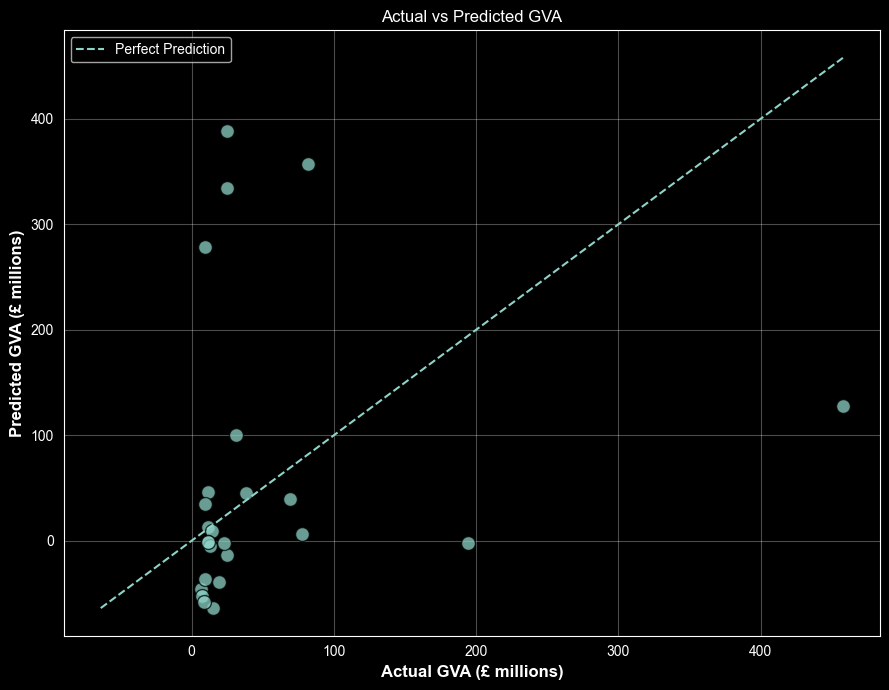

In [11]:
# 11. Plot actual GVA against predicted GVA
plt.figure(figsize=(9, 7))
plt.scatter(y_test, y_test_pred, s=100, alpha=0.75, edgecolor='black')

minimum_value = min(y_test.min(), y_test_pred.min())
maximum_value = max(y_test.max(), y_test_pred.max())

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle='--',
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted GVA')
plt.xlabel('Actual GVA (£ millions)', fontsize=12, weight='bold')
plt.ylabel('Predicted GVA (£ millions)', fontsize=12, weight='bold')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


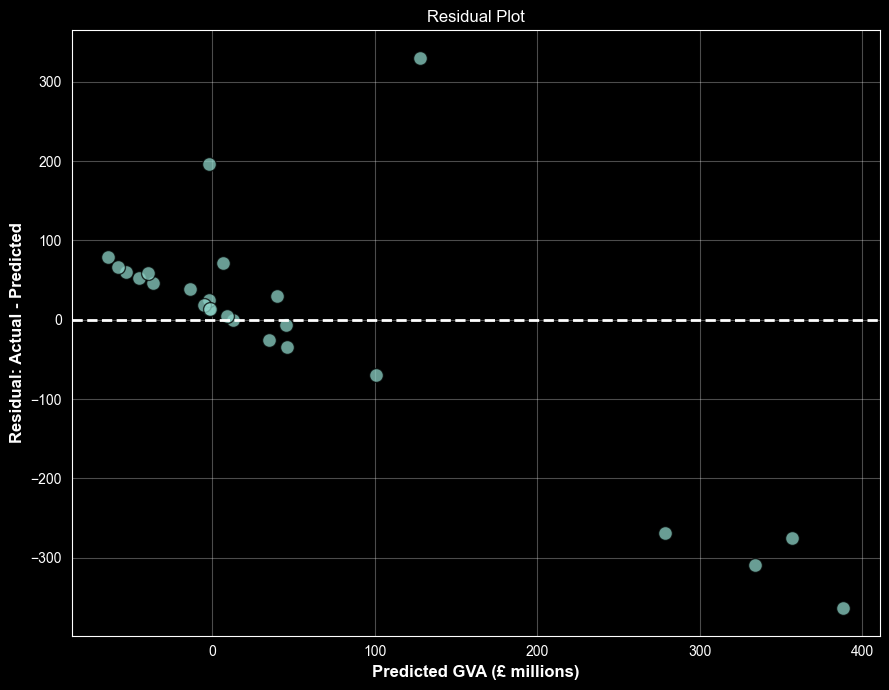

In [12]:
# 12. Plot the residuals
residuals = y_test - y_test_pred
plt.figure(figsize=(9, 7))
plt.scatter(y_test_pred, residuals, s=100, alpha=0.75, edgecolor='black')
plt.axhline(y=0, linestyle='--', linewidth=2)
plt.title('Residual Plot')
plt.xlabel('Predicted GVA (£ millions)', fontsize=12, weight='bold')
plt.ylabel('Residual: Actual - Predicted', fontsize=12, weight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()